In [17]:
# Write a Python program for an equilibrium conversion checker for the reaction A + B <=> C 
# with initial concentrations [A]0 = 1.5, [B]0 = 1.0, and [C]0 = 0. 
# The program should:
# 1. Read Kc using input(), print the data type of the raw input and converted value, 
#    and safely handle cases where the text is not a number or Kc <= 0 without crashing.
# 2. Find a, b, c, the discriminant, and both roots for the quadratic equation: Kc*x^2 - (2.5*Kc + 1)*x + 1.5*Kc = 0.
# 3. Select the physically meaningful root where 0 <= x <= 1 (since B is limiting).
# 4. Print equilibrium concentrations [A], [B], [C] to 3 decimal places and the conversion of limiting reactant B as a percentage.
# 5. Classify the conversion using if/elif/else: >= 70% as "High", >= 40% as "Moderate", otherwise "Low".

In [18]:
import math


def main():
    raw_kc = input("Enter Kc: ")
    print("Raw input type:", type(raw_kc))

    try:
        kc = float(raw_kc)
    except ValueError:
        print("Error: Kc must be a number.")
        return

    print("Converted Kc:", kc)
    print("Converted value type:", type(kc))

    if not math.isfinite(kc) or kc <= 0:
        print("Error: Kc must be a finite number greater than 0.")
        return

    a = kc
    b = -(2.5 * kc + 1)
    c = 1.5 * kc
    discriminant = b**2 - 4 * a * c

    if discriminant < 0:
        print("Error: The quadratic has no real roots.")
        return

    root1 = (-b + math.sqrt(discriminant)) / (2 * a)
    root2 = (-b - math.sqrt(discriminant)) / (2 * a)

    print(f"a = {a}")
    print(f"b = {b}")
    print(f"c = {c}")
    print(f"Discriminant = {discriminant}")
    print(f"Root 1 = {root1}")
    print(f"Root 2 = {root2}")

    physical_roots = [root for root in (root1, root2) if 0 <= root <= 1]
    if not physical_roots:
        print("Error: No physically meaningful root was found.")
        return

    x = physical_roots[0]
    equilibrium_a = 1.5 - x
    equilibrium_b = 1.0 - x
    equilibrium_c = x
    conversion_percent = (x / 1.0) * 100

    print(f"Equilibrium [A] = {equilibrium_a:.3f}")
    print(f"Equilibrium [B] = {equilibrium_b:.3f}")
    print(f"Equilibrium [C] = {equilibrium_c:.3f}")
    print(f"Conversion of limiting reactant B = {conversion_percent:.3f}%")

    if conversion_percent >= 70:
        classification = "High"
    elif conversion_percent >= 40:
        classification = "Moderate"
    else:
        classification = "Low"

    print(f"Conversion classification: {classification}")


main()

Raw input type: <class 'str'>
Converted Kc: 4.0
Converted value type: <class 'float'>
a = 4.0
b = -11.0
c = 6.0
Discriminant = 25.0
Root 1 = 2.0
Root 2 = 0.75
Equilibrium [A] = 0.750
Equilibrium [B] = 0.250
Equilibrium [C] = 0.750
Conversion of limiting reactant B = 75.000%
Conversion classification: High


In [ ]:
# Write a Python program with two parts:
# Part A: Simulate a batch reactor consumption of reactant A using the Euler method (C_new = C_old - k * C_old * dt) 
#         with C0 = 2.5, k = 0.04, and dt = 1. 
#         - Use a for loop to simulate 12 minutes and print a table of Time (min), Concentration (mol/L), and Conversion (%).
#         - Use math.exp() to calculate the exact value C0 * e^(-kt) at 12 min and print the absolute error of the Euler result.
#         - Use a while loop to repeat the simulation until conversion reaches 40% or time reaches 100 min, printing time and final concentration.
# Part B: Write a function to analyze distillation-column sample codes stored as text (e.g., "DIST2026X9Q3"). 
#         Loop through each character to print the number of digits and the sum of the digits. 
#         Handle and show clear messages for an empty code and a code with no digits. Test with "DIST2026X9Q3", an empty code, and "ABCDEF".

In [3]:
import math

# Part A: Euler simulation for 12 minutes, starting with the initial concentration.
initial_concentration = 2.5
rate_constant = 0.04
time_step = 1
concentration = initial_concentration

print("Time (min)\tConcentration (mol/L)\tConversion (%)")
for time in range(13):
    conversion = (initial_concentration - concentration) / initial_concentration * 100
    print(f"{time}\t\t{concentration:.4f}\t\t\t{conversion:.2f}")

    if time < 12:
        # Apply C_new = C_old - k * C_old * dt once per minute.
        concentration = concentration - rate_constant * concentration * time_step

euler_concentration = concentration
exact_concentration = initial_concentration * math.exp(-rate_constant * 12)
absolute_error = abs(euler_concentration - exact_concentration)
print(f"\nExact concentration at 12 min: {exact_concentration:.6f} mol/L")
print(f"Absolute error at 12 min: {absolute_error:.6f} mol/L")

# Restart from C0 and step until conversion reaches 40% or 100 minutes.
concentration = initial_concentration
time = 0
conversion = 0
while conversion < 40 and time < 100:
    concentration = concentration - rate_constant * concentration * time_step
    time += time_step
    conversion = (initial_concentration - concentration) / initial_concentration * 100

print(f"\n40% conversion target reached at time: {time} min")
print(f"Concentration at that time: {concentration:.4f} mol/L")


# Part B: Count digit characters and add their numeric values.
def analyze_sample_code(code):
    if code == "":
        print("The sample code is empty.")
        return

    digit_count = 0
    digit_sum = 0
    for character in code:
        if character.isdigit():
            digit_count += 1
            digit_sum += int(character)

    if digit_count == 0:
        print(f"No digits were found in code {code!r}.")
    else:
        print(f"Code: {code}")
        print(f"Number of digits: {digit_count}")
        print(f"Sum of digits: {digit_sum}")


print("\nSample-code analysis:")
analyze_sample_code("DIST2026X9Q3")
analyze_sample_code("")
analyze_sample_code("ABCDEF")

Time (min)	Concentration (mol/L)	Conversion (%)
0		2.5000			0.00
1		2.4000			4.00
2		2.3040			7.84
3		2.2118			11.53
4		2.1234			15.07
5		2.0384			18.46
6		1.9569			21.72
7		1.8786			24.86
8		1.8035			27.86
9		1.7313			30.75
10		1.6621			33.52
11		1.5956			36.18
12		1.5318			38.73

Exact concentration at 12 min: 1.546958 mol/L
Absolute error at 12 min: 0.015184 mol/L

40% conversion target reached at time: 13 min
Concentration at that time: 1.4705 mol/L

Sample-code analysis:
Code: DIST2026X9Q3
Number of digits: 6
Sum of digits: 22
The sample code is empty.
No digits were found in code 'ABCDEF'.


In [ ]:
# Write a Python program with two parts:
# Part A: Write a recursive function factorial(n) (handling base case 0!) and a combination function combination(n, r) 
#         that computes n! / (r! * (n - r)!). Reject invalid inputs (negative values, r > n). 
#         Print the number of mixtures for n = 9, r = 3, and show an error message for n = 6, r = 8.
# Part B: During a crystallization run, samples are taken at times = Fibonacci number * 4 min. 
#         Write an iterative function fib_iter(n) returning a list of the first n Fibonacci numbers, 
#         and a recursive function fib_rec(k) returning the k-th Fibonacci number (F0 = 0, F1 = 1). 
#         For n = 10, verify both functions agree and print a table showing: Sample No. | Fibonacci tag | Sampling time (min).

In [5]:
# Part A: Recursive factorial and combination calculations.
def factorial(n):
    if n < 0:
        raise ValueError("Factorial is not defined for negative values.")
    if n == 0 or n == 1:
        return 1
    return n * factorial(n - 1)


def combination(n, r):
    if n < 0 or r < 0 or r > n:
        raise ValueError("Invalid inputs: require n >= 0 and 0 <= r <= n.")
    return factorial(n) // (factorial(r) * factorial(n - r))


print("Part A: Mixture combinations")
print(f"Number of mixtures for n=9, r=3: {combination(9, 3)}")

try:
    print(f"Number of mixtures for n=6, r=8: {combination(6, 8)}")
except ValueError as error:
    print(f"Error: {error}")


# Part B: Iterative and recursive Fibonacci functions.
def fib_iter(n):
    if n < 0:
        raise ValueError("n must be non-negative.")

    numbers = []
    current, following = 0, 1
    for _ in range(n):
        numbers.append(current)
        current, following = following, current + following
    return numbers


def fib_rec(k):
    if k < 0:
        raise ValueError("k must be non-negative.")
    if k == 0:
        return 0
    if k == 1:
        return 1
    return fib_rec(k - 1) + fib_rec(k - 2)


number_of_samples = 10
fibonacci_numbers = fib_iter(number_of_samples)
recursive_numbers = [fib_rec(index) for index in range(number_of_samples)]

if fibonacci_numbers == recursive_numbers:
    print("\nPart B: Iterative and recursive Fibonacci results agree.")
else:
    print("\nError: Fibonacci results do not agree.")

print("Sample No.\tFibonacci tag\tSampling time (min)")
for sample_number, (index, fibonacci_number) in enumerate(
    enumerate(fibonacci_numbers), start=1
):
    sampling_time = fibonacci_number * 4
    print(f"{sample_number}\t\tF{index} ({fibonacci_number})\t\t{sampling_time}")

Part A: Mixture combinations
Number of mixtures for n=9, r=3: 84
Error: Invalid inputs: require n >= 0 and 0 <= r <= n.

Part B: Iterative and recursive Fibonacci results agree.
Sample No.	Fibonacci tag	Sampling time (min)
1		F0 (0)		0
2		F1 (1)		4
3		F2 (1)		4
4		F3 (2)		8
5		F4 (3)		12
6		F5 (5)		20
7		F6 (8)		32
8		F7 (13)		52
9		F8 (21)		84
10		F9 (34)		136


In [19]:
# Write a Python script using pandas and matplotlib to analyze kinetics and gas data:
# Part A: Create a DataFrame for the reactor catalyst kinetics table (Time_min, Run1_mol_L, Run2_mol_L). 
#         Save it as 'kinetics.csv' (without index column) and 'kinetics.json'. 
#         Read the CSV back into a new DataFrame and print its shape and data types.
# Part B: Print the mean and standard deviation of Run1 and Run2, and state which run shows more variation.
# Part C: Plot both runs on a single graph with Time on the x-axis, including a title, axis labels with units, legend, and grid.
# Part D: For the ethylene gas compression data (Volume_L: 1 to 5, Pressure_bar: 5.03, 2.52, 1.65, 1.26, 1.01):
#         - Plot pressure vs. volume as a scatter plot.
#         - Calculate k as the mean of P * V.
#         - Draw the reference curve P = k / V on the same graph.
#         - Add a title, axis labels with units, and a legend.

CSV shape: (6, 3)
CSV data types:
 Time_min        int64
Run1_mol_L    float64
Run2_mol_L    float64
dtype: object

Run 1: mean = 0.878, standard deviation = 0.402
Run 2: mean = 0.645, standard deviation = 0.507
Run 2 shows more variation.


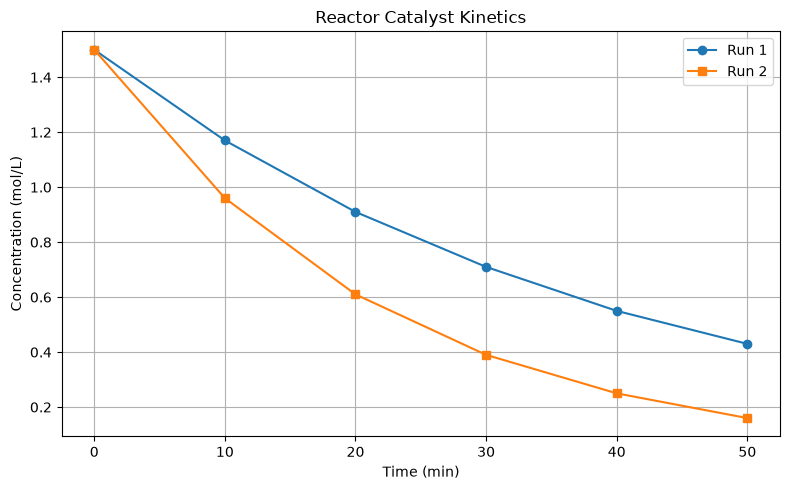


Mean PV constant, k = 5.022 bar·L


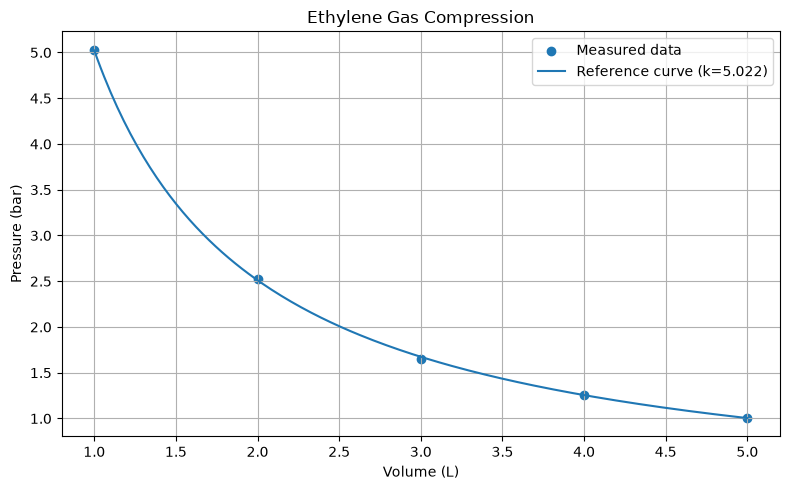

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Run 1 uses the illustrative kinetics data from Practical 10.
# Run 2 is illustrative because no second series was specified.
kinetics_df = pd.DataFrame({
    "Time_min": [0,  10,  20,  30, 40, 50],
    "Run1_mol_L": [ 1.50, 1.17, 0.91,0.71, 0.55, 0.43],
    "Run2_mol_L": [1.50, 0.96, 0.61, 0.39, 0.25, 0.16],
})

# Save both formats, then read the CSV back and inspect it.
kinetics_df.to_csv("kinetics.csv", index=False)
kinetics_df.to_json("kinetics.json", orient="records", indent=2)

kinetics_readback = pd.read_csv("kinetics.csv")
print("CSV shape:", kinetics_readback.shape)
print("CSV data types:\n", kinetics_readback.dtypes)

# Compare the mean and sample standard deviation of each run.
run1_mean = kinetics_readback["Run1_mol_L"].mean()
run1_std = kinetics_readback["Run1_mol_L"].std()
run2_mean = kinetics_readback["Run2_mol_L"].mean()
run2_std = kinetics_readback["Run2_mol_L"].std()

print(f"\nRun 1: mean = {run1_mean:.3f}, standard deviation = {run1_std:.3f}")
print(f"Run 2: mean = {run2_mean:.3f}, standard deviation = {run2_std:.3f}")

if run1_std > run2_std:
    print("Run 1 shows more variation.")
elif run2_std > run1_std:
    print("Run 2 shows more variation.")
else:
    print("Both runs show equal variation.")

# Plot both kinetics runs against time.
plt.figure(figsize=(8, 5))
plt.plot(kinetics_readback["Time_min"], kinetics_readback["Run1_mol_L"],
         marker="o", label="Run 1")
plt.plot(kinetics_readback["Time_min"], kinetics_readback["Run2_mol_L"],
         marker="s", label="Run 2")
plt.title("Reactor Catalyst Kinetics")
plt.xlabel("Time (min)")
plt.ylabel("Concentration (mol/L)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Gas compression data and mean PV value.
gas_data = pd.DataFrame({
    "Volume_L": [1, 2, 3, 4, 5],
    "Pressure_bar": [5.03, 2.52, 1.65, 1.26, 1.01],
})
k = (gas_data["Volume_L"] * gas_data["Pressure_bar"]).mean()
print(f"\nMean PV constant, k = {k:.3f} bar·L")

# Plot measured pressures and the reference curve P = k / V.
volume_curve = np.linspace(gas_data["Volume_L"].min(),
                           gas_data["Volume_L"].max(), 200)
pressure_curve = k / volume_curve

plt.figure(figsize=(8, 5))
plt.scatter(gas_data["Volume_L"], gas_data["Pressure_bar"],
            label="Measured data")
plt.plot(volume_curve, pressure_curve, label=f"Reference curve (k={k:.3f})")
plt.title("Ethylene Gas Compression")
plt.xlabel("Volume (L)")
plt.ylabel("Pressure (bar)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()